# Compare signal-discovery results

Choose any two of MiniLM, Decider, and Qwen3 reranker in COMPARE_MODELS in the first code cell, then rerun the comparison cells below. The table compares candidate ranks; the full scatter emphasizes candidates by their average normalized weight. The comparison also reports Jensen–Shannon divergence and shared weight mass for the candidate distributions. Decider supplies choice probabilities; MiniLM and Qwen3 use normalized softmax ranking weights, which are not calibrated relevance probabilities. These rankings are suggestions, not ground-truth relevance labels. Original results are loaded separately in the prompt-sensitivity section.

In [107]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RESULT_FILES = {
    'MiniLM': Path('/storage/lcostes/ray-share/experiments/simbench-signals/minilm.jsonl'),
    'Decider': Path('/storage/lcostes/ray-share/experiments/simbench-signals/decider.jsonl'),
    'Qwen3 reranker': Path('/storage/lcostes/ray-share/experiments/simbench-signals/qwen3-reranker.jsonl'),
}

# Select any two distinct model names from RESULT_FILES, then rerun this and the comparison cells.
COMPARE_MODELS = ('Qwen3 reranker', 'Decider')
if len(COMPARE_MODELS) != 2 or COMPARE_MODELS[0] == COMPARE_MODELS[1]:
    raise ValueError('COMPARE_MODELS must contain two different model names')
unknown_models = set(COMPARE_MODELS) - set(RESULT_FILES)
if unknown_models:
    raise ValueError(f'Unknown model(s): {sorted(unknown_models)}')

def load_jsonl(path):
    with path.open(encoding='utf-8') as f:
        return [json.loads(line) for line in f if line.strip()]

RESULTS = {name: {row['condition_id']: row for row in load_jsonl(path)}
           for name, path in RESULT_FILES.items()}
CONDITION_IDS = sorted(set.intersection(*(set(RESULTS[name]) for name in COMPARE_MODELS)))
if not CONDITION_IDS:
    raise ValueError(f'No shared conditions for {COMPARE_MODELS}')
print(f'Comparing {COMPARE_MODELS[0]} vs {COMPARE_MODELS[1]}; {len(CONDITION_IDS)} shared conditions.')

Comparing Qwen3 reranker vs Decider; 5 shared conditions.


In [108]:
# Quick overview: condition wording and each selected method’s top-ranked signal.
def _top_signal_id(row):
    probabilities = row.get('choice_probabilities') or {}
    if probabilities:
        return max(probabilities, key=lambda key: (float(probabilities[key]), key))
    return max(row['signals'], key=lambda signal: float(signal.get('score', 0)))['id']

overview = []
for condition_id in CONDITION_IDS:
    row = RESULTS[COMPARE_MODELS[0]][condition_id]
    record = {'condition': condition_id, 'intent': row['condition']}
    for model in COMPARE_MODELS:
        record[f'{model} top signal'] = _top_signal_id(RESULTS[model][condition_id])
    overview.append(record)
display(pd.DataFrame(overview).set_index('condition'))

,intent,Qwen3 reranker top signal,Decider top signal
condition,,,
condition-001,I'm looking for products that serve similar pu...,attribute:customer:customer>review>product:pro...,attribute:review:review>product:product.descri...
condition-002,Which products appeal to similar customers bas...,attribute:customer:customer>review>product:pro...,relationship:product:product>review>customer
condition-003,Show me reviews that provide useful insights i...,attribute:product:product>review:review.review...,attribute:review:review:review.review_text
condition-004,Prioritize products that offer a good balance ...,attribute:customer:customer>review>product:pro...,attribute:review:review:review.rating
condition-005,I'd like to discover customers with similar ta...,attribute:customer:customer>review:review.rating,attribute:review:review:review.rating


In [109]:
def _ranked(row, method):
    # Decider has probabilities for every candidate; pairwise rankers store
    # all candidate scores in `signals`.
    probabilities = row.get('choice_probabilities') or {}
    if probabilities:
        ordered_ids = [signal_id for signal_id, _ in sorted(
            probabilities.items(), key=lambda item: (-float(item[1]), item[0])
        )]
    else:
        ordered_ids = [s['id'] for s in sorted(
            row['signals'], key=lambda s: float(s.get('score', 0)), reverse=True
        )]
    return pd.DataFrame({
        'signal_id': ordered_ids,
        f'{method} rank': range(1, len(ordered_ids) + 1),
    })

def _normalized_candidate_weights(model, row):
    # Decider's probabilities are already normalized choice weights. For the
    # pairwise rankers, softmax the raw ranking logits across candidates.
    probabilities = row.get('choice_probabilities') or {}
    if probabilities:
        weights = {str(key): max(0.0, float(value)) for key, value in probabilities.items()}
    else:
        logits = {}
        for signal in row.get('signals', []):
            if 'ranking_logit' in signal:
                logit = float(signal['ranking_logit'])
            else:
                score = min(max(float(signal.get('score', 0.0)), 1e-12), 1 - 1e-12)
                logit = math.log(score) - math.log1p(-score)
            logits[str(signal['id'])] = logit
        if not logits:
            raise ValueError(f'No ranked candidates in {model} result')
        offset = max(logits.values())
        weights = {key: math.exp(value - offset) for key, value in logits.items()}
    total = sum(weights.values())
    if total <= 0:
        raise ValueError(f'{model} candidate weights have zero mass')
    return {key: value / total for key, value in weights.items()}


def _jensen_shannon_divergence(p, q):
    if set(p) != set(q):
        raise ValueError('Jensen-Shannon inputs must contain the same candidates')
    divergence = 0.0
    for key in p:
        midpoint = (p[key] + q[key]) / 2
        if p[key] > 0:
            divergence += 0.5 * p[key] * math.log2(p[key] / midpoint)
        if q[key] > 0:
            divergence += 0.5 * q[key] * math.log2(q[key] / midpoint)
    return divergence


def compare_condition(condition_id, top_n=15):
    if condition_id not in CONDITION_IDS:
        raise KeyError(f'No paired result for {condition_id} and {COMPARE_MODELS}')
    rows = {model: RESULTS[model][condition_id] for model in COMPARE_MODELS}
    ranked = {model: _ranked(rows[model], model) for model in COMPARE_MODELS}

    # Candidate descriptions/routes are shared metadata, not model-specific.
    catalog = {s['id']: s for row in rows.values() for s in row.get('signals', [])}
    all_signal_ids = set().union(*(set(frame['signal_id']) for frame in ranked.values()))
    comparison = pd.DataFrame([
        {
            'signal_id': signal_id,
            'kind': (s := catalog.get(signal_id, {})).get('kind'),
            'signal': (f"{s.get('attribute_table')}.{s.get('attribute_column')}"
                       if s.get('kind') == 'attribute' else 'relationship'),
            'route': ' → '.join(s.get('path') or []),
        }
        for signal_id in all_signal_ids
    ])
    for model, frame in ranked.items():
        comparison = comparison.merge(frame, on='signal_id', how='left')
    rank_columns = [f'{model} rank' for model in COMPARE_MODELS]
    comparison['best rank'] = comparison[rank_columns].min(axis=1)
    comparison = comparison.sort_values(['best rank', *rank_columns], na_position='last')
    print(rows[COMPARE_MODELS[0]]['condition'])
    print(f'Sorted by best (lowest) rank from {COMPARE_MODELS[0]} or {COMPARE_MODELS[1]}.')
    print('Top-k overlap (shared candidates among each method’s top k):')
    for k in (5, 10):
        a = set(ranked[COMPARE_MODELS[0]].head(k)['signal_id'])
        b = set(ranked[COMPARE_MODELS[1]].head(k)['signal_id'])
        denominator = min(k, len(a), len(b))
        print(f'  k={k}: {len(a & b)}/{denominator}')
    columns = ['kind', 'signal', 'route', *rank_columns]
    display(comparison[columns].head(top_n).style.format(
        {column: '{:.0f}' for column in rank_columns}, na_rep='—'
    ))
    model_a, model_b = COMPARE_MODELS
    weights_a = _normalized_candidate_weights(model_a, rows[model_a])
    weights_b = _normalized_candidate_weights(model_b, rows[model_b])
    shared_ids = sorted(set(weights_a) & set(weights_b))
    total_a = sum(weights_a[sid] for sid in shared_ids)
    total_b = sum(weights_b[sid] for sid in shared_ids)
    if total_a <= 0 or total_b <= 0:
        raise ValueError('Candidate weights must have positive total mass')
    p = {sid: weights_a[sid] / total_a for sid in shared_ids}
    q = {sid: weights_b[sid] / total_b for sid in shared_ids}
    js_divergence = _jensen_shannon_divergence(p, q)
    shared_mass = sum(min(p[sid], q[sid]) for sid in shared_ids)
    mean_weight = {sid: (p[sid] + q[sid]) / 2 for sid in shared_ids}
    print(f'Jensen–Shannon divergence: {js_divergence:.3f} bits (0 = identical, 1 = maximally different)')
    print(f'Shared normalized weight mass: {shared_mass:.3f} (1 = identical distributions)')

    paired = comparison.dropna(subset=rank_columns).copy()
    paired['mean normalized weight'] = paired['signal_id'].map(mean_weight)
    limit = max(len(ranked[model_a]), len(ranked[model_b]))
    point_weights = paired['mean normalized weight'].tolist()
    max_weight = max(point_weights) if point_weights else 1.0
    point_sizes = [35 + 1100 * weight / max_weight for weight in point_weights]
    fig, ax = plt.subplots(figsize=(7, 6))
    points = ax.scatter(
        paired[rank_columns[0]], paired[rank_columns[1]],
        c=point_weights, s=point_sizes, cmap='viridis',
        alpha=.85, edgecolors='black', linewidths=.25,
    )
    ax.plot([1, limit], [1, limit], '--', color='gray', linewidth=1)
    tick_step = max(1, limit // 8)
    rank_ticks = list(range(1, limit + 1, tick_step))
    if limit not in rank_ticks:
        rank_ticks.append(limit)
    ax.set(xlabel=f'{model_a} rank (1 = highest)',
           ylabel=f'{model_b} rank (1 = highest)',
           title=f'{condition_id}: full ranking comparison',
           xlim=(0.5, limit + 0.5), ylim=(0.5, limit + 0.5),
           xticks=rank_ticks, yticks=rank_ticks)
    ax.grid(alpha=.2)
    fig.colorbar(points, ax=ax, label='Mean normalized candidate weight')
    fig.tight_layout(); plt.show()

I'm looking for products that serve similar purposes, regardless of their brand or category.
Sorted by best (lowest) rank from Qwen3 reranker or Decider.
Top-k overlap (shared candidates among each method’s top k):
  k=5: 3/5
  k=10: 7/10


,kind,signal,route,Qwen3 reranker rank,Decider rank
10,attribute,product.description,customer → review → product,1,3
22,attribute,product.description,review → product,2,1
21,attribute,product.description,product,3,2
24,attribute,review.review_text,product → review,4,10
33,attribute,review.review_text,review,17,4
31,attribute,review.summary,product → review,5,8
35,attribute,review.summary,review,21,5
18,attribute,review.rating,product → review,6,18
19,relationship,relationship,product → review,10,6
14,attribute,review.review_text,customer → review,7,38


Jensen–Shannon divergence: 0.229 bits (0 = identical, 1 = maximally different)
Shared normalized weight mass: 0.531 (1 = identical distributions)


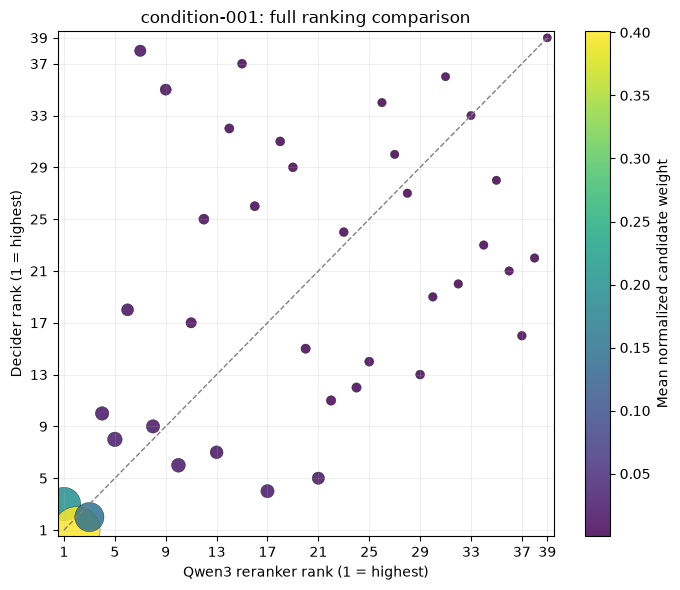

In [110]:
# Change this ID to browse a different intent.
compare_condition('condition-001', top_n=10)

## Across-condition comparison across all model pairs

This section evaluates all three model pairs over every shared condition. It reports rank correlation, Jensen–Shannon divergence, shared normalized weight mass, and top-k overlap per condition, plus mean and standard deviation across conditions. Each intent contributes equally to the summary. The normalized weights are relative ranking distributions, not calibrated relevance probabilities.

Mean ± standard deviation across shared conditions (lower JSD and higher shared mass/overlap mean closer distributions).


,Conditions,Spearman_mean,Spearman_sd,JSD_mean_bits,JSD_sd_bits,Shared_mass_mean,Shared_mass_sd,Top5_overlap_mean,Top10_overlap_mean
Model pair,,,,,,,,,
Decider vs Qwen3 reranker,5,0.418,0.095,0.379,0.130,0.382,0.097,3.0,6.4
MiniLM vs Decider,5,-0.252,0.354,0.553,0.184,0.279,0.143,1.0,2.4
MiniLM vs Qwen3 reranker,5,0.266,0.305,0.528,0.214,0.304,0.194,0.6,3.0


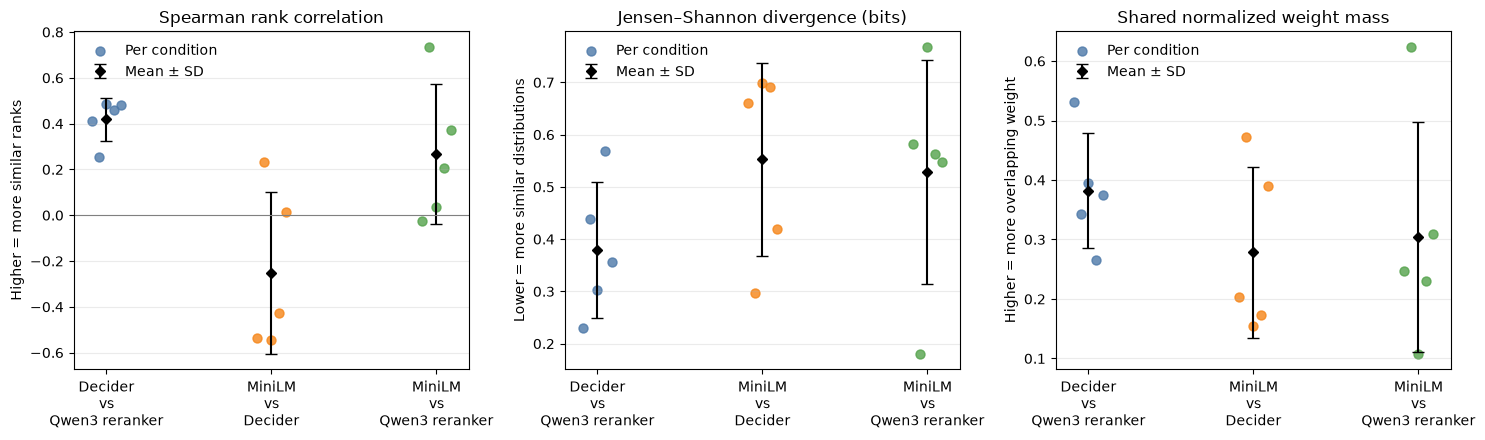

In [111]:
from itertools import combinations

PAIR_CONDITION_METRICS = []
MODEL_PAIRS = list(combinations(RESULT_FILES.keys(), 2))
for model_a, model_b in MODEL_PAIRS:
    condition_ids = sorted(set(RESULTS[model_a]) & set(RESULTS[model_b]))
    for condition_id in condition_ids:
        row_a, row_b = RESULTS[model_a][condition_id], RESULTS[model_b][condition_id]
        weights_a = _normalized_candidate_weights(model_a, row_a)
        weights_b = _normalized_candidate_weights(model_b, row_b)
        common_ids = sorted(set(weights_a) & set(weights_b))
        mass_a = sum(weights_a[key] for key in common_ids)
        mass_b = sum(weights_b[key] for key in common_ids)
        p = {key: weights_a[key] / mass_a for key in common_ids}
        q = {key: weights_b[key] / mass_b for key in common_ids}

        ranks_a = _ranked(row_a, model_a)
        ranks_b = _ranked(row_b, model_b)
        rank_a = dict(zip(ranks_a['signal_id'], ranks_a[f'{model_a} rank']))
        rank_b = dict(zip(ranks_b['signal_id'], ranks_b[f'{model_b} rank']))
        ranked_ids = sorted(set(rank_a) & set(rank_b))
        rho = pd.Series([rank_a[key] for key in ranked_ids]).corr(
            pd.Series([rank_b[key] for key in ranked_ids]), method="spearman"
        )
        top_k_overlap = {}
        for k in (5, 10):
            top_a = set(ranks_a.head(k)["signal_id"])
            top_b = set(ranks_b.head(k)["signal_id"])
            top_k_overlap[k] = len(top_a & top_b)
        PAIR_CONDITION_METRICS.append({
            "Model pair": f"{model_a} vs {model_b}",
            "Condition": condition_id,
            "Shared candidates": len(common_ids),
            "Spearman rho": float(rho),
            "JSD (bits)": _jensen_shannon_divergence(p, q),
            "Shared weight mass": sum(min(p[key], q[key]) for key in common_ids),
            "Top-5 overlap": top_k_overlap[5],
            "Top-10 overlap": top_k_overlap[10],
        })

PAIR_METRICS = pd.DataFrame(PAIR_CONDITION_METRICS)
SUMMARY = PAIR_METRICS.groupby("Model pair").agg(
    Conditions=("Condition", "nunique"),
    Spearman_mean=("Spearman rho", "mean"),
    Spearman_sd=("Spearman rho", "std"),
    JSD_mean_bits=("JSD (bits)", "mean"),
    JSD_sd_bits=("JSD (bits)", "std"),
    Shared_mass_mean=("Shared weight mass", "mean"),
    Shared_mass_sd=("Shared weight mass", "std"),
    Top5_overlap_mean=("Top-5 overlap", "mean"),
    Top10_overlap_mean=("Top-10 overlap", "mean"),
)
print("Mean ± standard deviation across shared conditions (lower JSD and higher shared mass/overlap mean closer distributions).")
display(SUMMARY.style.format({
    "Spearman_mean": "{:.3f}", "Spearman_sd": "{:.3f}",
    "JSD_mean_bits": "{:.3f}", "JSD_sd_bits": "{:.3f}",
    "Shared_mass_mean": "{:.3f}", "Shared_mass_sd": "{:.3f}",
    "Top5_overlap_mean": "{:.1f}", "Top10_overlap_mean": "{:.1f}",
}))
display(PAIR_METRICS.set_index(["Model pair", "Condition"]).style.format({
    "Spearman rho": "{:.3f}", "JSD (bits)": "{:.3f}",
    "Shared weight mass": "{:.3f}",
}))

pair_labels = list(SUMMARY.index)
colors = ["#4C78A8", "#F58518", "#54A24B"]
metric_specs = [
    ("Spearman rho", "Spearman rank correlation", "Higher = more similar ranks"),
    ("JSD (bits)", "Jensen–Shannon divergence (bits)", "Lower = more similar distributions"),
    ("Shared weight mass", "Shared normalized weight mass", "Higher = more overlapping weight"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (column, title, y_label) in zip(axes, metric_specs):
    for index, pair_label in enumerate(pair_labels):
        values = PAIR_METRICS.loc[PAIR_METRICS["Model pair"] == pair_label, column].tolist()
        offsets = [(j - (len(values) - 1) / 2) * 0.045 for j in range(len(values))]
        ax.scatter([index + offset for offset in offsets], values,
                   color=colors[index], alpha=.8, s=42, label="Per condition" if index == 0 else None)
        mean_col = {"Spearman rho": "Spearman_mean", "JSD (bits)": "JSD_mean_bits", "Shared weight mass": "Shared_mass_mean"}[column]
        mean = SUMMARY.loc[pair_label, mean_col]
        sd_col = {"Spearman rho": "Spearman_sd", "JSD (bits)": "JSD_sd_bits", "Shared weight mass": "Shared_mass_sd"}[column]
        ax.errorbar(index, mean, yerr=SUMMARY.loc[pair_label, sd_col],
                    fmt="D", color="black", capsize=4, markersize=5,
                    label="Mean ± SD" if index == 0 else None)
    ax.set(title=title, ylabel=y_label, xticks=range(len(pair_labels)),
           xticklabels=[label.replace(" vs ", "\nvs\n") for label in pair_labels])
    ax.grid(axis="y", alpha=.25)
    if column == "Spearman rho":
        ax.axhline(0, color="gray", linewidth=.8)
    ax.legend(frameon=False)
fig.tight_layout(); plt.show()

## Top-p signal selection

For a chosen condition and cumulative top-p threshold, this selects the shortest ranked prefix whose normalized weights sum to at least top_p. Decider uses its returned choice probabilities; MiniLM and Qwen3 reranker use a softmax over their ranking logits. The older MiniLM file stores sigmoid scores, so the cell recovers logits from those scores when ranking_logit is absent. These are relative ranking weights, not calibrated relevance probabilities. Edit CONDITION_ID and TOP_P, then rerun the cell.

In [112]:
CONDITION_ID = 'condition-001'
TOP_P = 0.80

def _inverse_sigmoid(score):
    score = np.clip(float(score), np.finfo(float).tiny, 1 - np.finfo(float).eps)
    return np.log(score) - np.log1p(-score)

def _selection_distribution(model, row):
    if model == 'Decider':
        scores = row['choice_probabilities']
        ordered = sorted(scores.items(), key=lambda item: (-float(item[1]), item[0]))
        ids = [signal_id for signal_id, _ in ordered]
        probs = np.array([float(score) for _, score in ordered], dtype=float)
        probs = probs / probs.sum()
        return ids, probs
    ordered = sorted(row['signals'], key=lambda s: float(s.get('score', 0)), reverse=True)
    ids = [signal['id'] for signal in ordered]
    scores = np.array([
        float(signal['ranking_logit']) if 'ranking_logit' in signal
        else _inverse_sigmoid(signal['score'])
        for signal in ordered
    ], dtype=float)
    weights = np.exp(scores - scores.max())
    return ids, weights / weights.sum()

def _signal_description(row, signal_id):
    signal = next((s for s in row['signals'] if s['id'] == signal_id), None)
    if signal is None:
        return signal_id, ''
    if signal.get('kind') == 'attribute':
        label = f"{signal.get('attribute_table')}.{signal.get('attribute_column')}"
    else:
        label = 'relationship'
    return label, ' → '.join(signal.get('path', []))

def show_top_p_selection(condition_id=CONDITION_ID, top_p=TOP_P):
    if not 0 < top_p <= 1:
        raise ValueError('top_p must be in (0, 1]')
    for model in ('MiniLM', 'Decider', 'Qwen3 reranker'):
        row = RESULTS[model][condition_id]
        ids, probs = _selection_distribution(model, row)
        cumulative = np.cumsum(probs)
        count = min(int(np.searchsorted(cumulative, top_p, side='left')) + 1, len(ids))
        records = []
        for rank, (signal_id, probability, cum_prob) in enumerate(zip(ids[:count], probs[:count], cumulative[:count]), 1):
            label, path = _signal_description(row, signal_id)
            records.append({'Rank': rank, 'Signal': label, 'Path': path,
                           'Normalized weight': probability, 'Cumulative weight': cum_prob})
        print(f'{model}: {count} signal(s) selected at top_p={top_p:.2f}; cumulative mass={cumulative[count-1]:.3f}')
        display(pd.DataFrame(records).style.format({'Normalized weight': '{:.4f}', 'Cumulative weight': '{:.4f}'}))

show_top_p_selection()

MiniLM: 18 signal(s) selected at top_p=0.80; cumulative mass=0.809


,Rank,Signal,Path,Normalized weight,Cumulative weight
0,1,relationship,customer → review → product,0.1254,0.1254
1,2,relationship,product → review → customer,0.1227,0.2481
2,3,relationship,review → customer,0.0662,0.3143
3,4,relationship,customer → review,0.0616,0.3758
4,5,product.title,customer → review → product,0.0468,0.4227
5,6,product.price,customer → review → product,0.0417,0.4644
6,7,customer.customer_name,product → review → customer,0.0380,0.5024
7,8,product.brand,customer → review → product,0.0367,0.5391
8,9,product.category,customer → review → product,0.0349,0.5739
9,10,product.description,customer → review → product,0.0329,0.6068


Decider: 4 signal(s) selected at top_p=0.80; cumulative mass=0.801


,Rank,Signal,Path,Normalized weight,Cumulative weight
0,1,product.description,review → product,0.5751,0.5751
1,2,product.description,product,0.1407,0.7159
2,3,product.description,customer → review → product,0.0483,0.7642
3,4,review.review_text,review,0.0364,0.8006


Qwen3 reranker: 5 signal(s) selected at top_p=0.80; cumulative mass=0.803


,Rank,Signal,Path,Normalized weight,Cumulative weight
0,1,product.description,customer → review → product,0.3508,0.3508
1,2,product.description,review → product,0.2265,0.5774
2,3,product.description,product,0.1557,0.7330
3,4,review.review_text,product → review,0.0347,0.7678
4,5,review.summary,product → review,0.0347,0.8025
